<a href="https://colab.research.google.com/github/Nazarchona/MachineLearning/blob/main/%D0%9B%D0%A010_%D0%93%D1%83%D1%94%D0%B2%D0%9D%D0%B0%D0%B7%D0%B0%D1%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** ______________________________  
**Група:** ______________________________  
**Дата:** ______________________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from IPython.display import Markdown, display

keras.utils.set_random_seed(42)      # відтворюваність (початкові ваги, перемішування)
print('TensorFlow:', tf.__version__)
print('Keras:', keras.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['Футболка', 'Штани', 'Светр', 'Сукня', 'Пальто',
               'Сандалі', 'Сорочка', 'Кросівки', 'Сумка', 'Черевики']

print('x_train:', x_train.shape, x_train.dtype)
print('y_train:', y_train.shape)
print('x_test :', x_test.shape)
print('y_test :', y_test.shape)
print('Кількість класів:', len(class_names))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 28, 28) uint8
y_train: (60000,)
x_test : (10000, 28, 28)
y_test : (10000,)
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

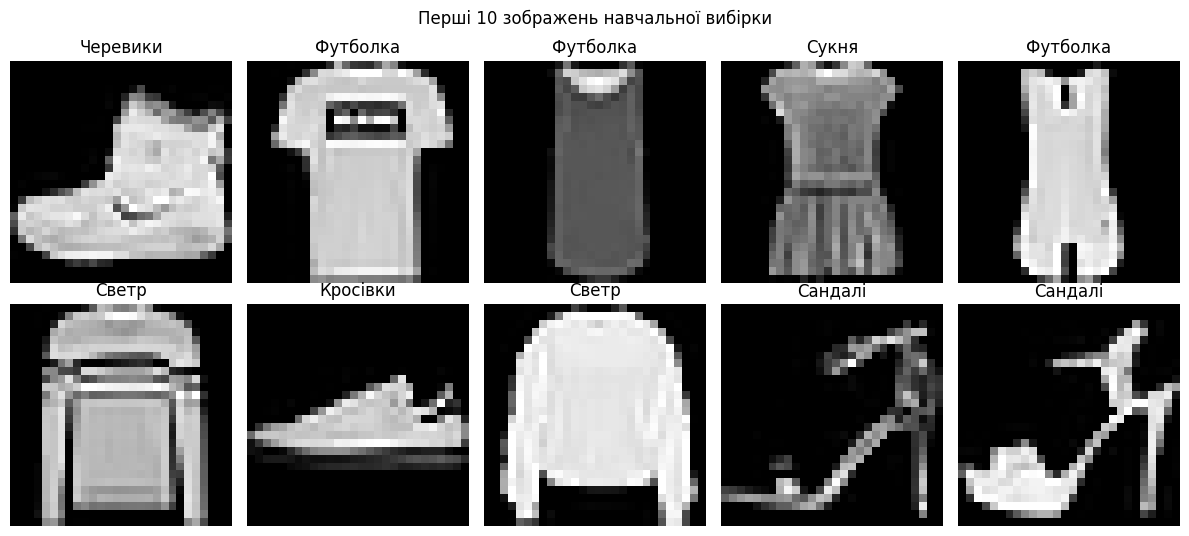

In [3]:
plt.figure(figsize=(12, 5.5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.suptitle('Перші 10 зображень навчальної вибірки')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
print('До нормалізації :', x_train.dtype, x_train.min(), x_train.max())

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print('Після нормалізації:', x_train.dtype, x_train.min(), x_train.max())
print('Тест             :', x_test.dtype, x_test.min(), x_test.max())

До нормалізації : uint8 0 255
Після нормалізації: float32 0.0 1.0
Тест             : float32 0.0 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
LEARNING_RATE_1 = 0.001

model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),                         # 28x28 -> вектор із 784 значень
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax'),   # 10 класів
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE_1),
    loss='sparse_categorical_crossentropy',   # цілочисельні мітки класів
    metrics=['accuracy'],
)

**Пояснення вибору гіперпараметрів.**

- **Нейрони (256 → 128).** Вхід має 784 ознаки, тому перший прихований шар достатньо широкий, щоб виділити складні комбінації пікселів, а другий вдвічі вужчий — поступово стискає подання перед виходом на 10 класів. Більші шари мали б більше параметрів і більший ризик перенавчання без помітного приросту якості на такому простому датасеті.
- **Dropout = 0,3.** Випадково «вимикає» 30 % нейронів під час навчання, що зменшує співадаптацію нейронів і перенавчання; значення 0,2–0,5 є типовим компромісом між регуляризацією та втратою інформації.
- **Швидкість навчання = 0,001** — стандартне значення для Adam: достатньо мала, щоб навчання було стабільним, і достатньо велика, щоб збігатися за кілька десятків епох. Додатково її знижує `ReduceLROnPlateau`.
- **Вихід:** 10 нейронів із softmax дають розподіл ймовірностей по класах; функція втрат `sparse_categorical_crossentropy` підходить для цілочисельних міток.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Окрема валідаційна частина (10 %) із навчальних даних; тест не використовується
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42, stratify=y_train)
print('train:', x_tr.shape, ' val:', x_val.shape)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]

history = model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=callbacks,
    verbose=2,
)
print('Епох виконано:', len(history.history['loss']))

train: (54000, 28, 28)  val: (6000, 28, 28)
Epoch 1/50
422/422 - 6s - 15ms/step - accuracy: 0.7738 - loss: 0.6361 - val_accuracy: 0.8495 - val_loss: 0.4158 - learning_rate: 0.0010
Epoch 2/50
422/422 - 4s - 9ms/step - accuracy: 0.8382 - loss: 0.4467 - val_accuracy: 0.8683 - val_loss: 0.3637 - learning_rate: 0.0010
Epoch 3/50
422/422 - 4s - 9ms/step - accuracy: 0.8532 - loss: 0.4050 - val_accuracy: 0.8767 - val_loss: 0.3346 - learning_rate: 0.0010
Epoch 4/50
422/422 - 5s - 11ms/step - accuracy: 0.8634 - loss: 0.3780 - val_accuracy: 0.8845 - val_loss: 0.3218 - learning_rate: 0.0010
Epoch 5/50
422/422 - 3s - 8ms/step - accuracy: 0.8674 - loss: 0.3593 - val_accuracy: 0.8847 - val_loss: 0.3170 - learning_rate: 0.0010
Epoch 6/50
422/422 - 3s - 8ms/step - accuracy: 0.8715 - loss: 0.3455 - val_accuracy: 0.8882 - val_loss: 0.3110 - learning_rate: 0.0010
Epoch 7/50
422/422 - 4s - 9ms/step - accuracy: 0.8776 - loss: 0.3332 - val_accuracy: 0.8858 - val_loss: 0.3049 - learning_rate: 0.0010
Epoch 8/5

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()
print('Кількість шарів у моделі  :', len(model.layers))
print('Кількість параметрів      :', model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів у моделі  : 6
Кількість параметрів      : 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# За потреби збереження на Google Drive (розкоментуйте):
# from google.colab import drive
# drive.mount('/content/drive')
# MODEL_PATH = '/content/drive/MyDrive/fashion_mnist_model.keras'

MODEL_PATH = 'fashion_mnist_model.keras'
model.save(MODEL_PATH)
print('Модель збережено:', os.path.abspath(MODEL_PATH))

# Перевірка: завантаження збереженої моделі
loaded = keras.models.load_model(MODEL_PATH)
print('Модель успішно завантажено, параметрів:', loaded.count_params())

Модель збережено: /content/fashion_mnist_model.keras
Модель успішно завантажено, параметрів: 235146


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

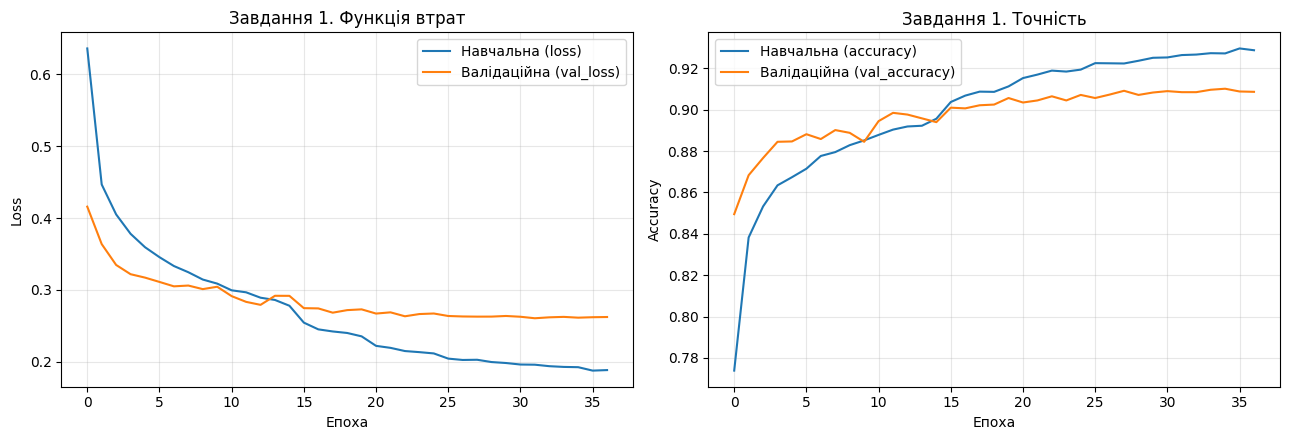

In [9]:
def plot_history(hist, title_prefix=''):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(hist.history['loss'], label='Навчальна (loss)')
    axes[0].plot(hist.history['val_loss'], label='Валідаційна (val_loss)')
    axes[0].set_title(f'{title_prefix}Функція втрат')
    axes[0].set_xlabel('Епоха'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(alpha=.3)

    axes[1].plot(hist.history['accuracy'], label='Навчальна (accuracy)')
    axes[1].plot(hist.history['val_accuracy'], label='Валідаційна (val_accuracy)')
    axes[1].set_title(f'{title_prefix}Точність')
    axes[1].set_xlabel('Епоха'); axes[1].set_ylabel('Accuracy'); axes[1].legend(); axes[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_history(history, 'Завдання 1. ')

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Єдине оцінювання на тестовій вибірці
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss     : {test_loss:.4f}')
print(f'Test accuracy : {test_acc:.4f}')

y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)

print('\nКласифікаційний звіт:\n')
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

THRESHOLD = 0.87
print(f'Поріг {THRESHOLD}: ', 'ВИКОНАНО ✔' if test_acc >= THRESHOLD else 'НЕ виконано ✘',
      f'(accuracy = {test_acc:.4f})')

Test loss     : 0.3065
Test accuracy : 0.8961

Класифікаційний звіт:

              precision    recall  f1-score   support

    Футболка     0.8346    0.8530    0.8437      1000
       Штани     0.9939    0.9750    0.9844      1000
       Светр     0.8139    0.8220    0.8179      1000
       Сукня     0.8918    0.9070    0.8994      1000
      Пальто     0.8256    0.8330    0.8293      1000
     Сандалі     0.9848    0.9720    0.9784      1000
     Сорочка     0.7226    0.6930    0.7075      1000
    Кросівки     0.9473    0.9700    0.9585      1000
       Сумка     0.9789    0.9760    0.9775      1000
    Черевики     0.9658    0.9600    0.9629      1000

    accuracy                         0.8961     10000
   macro avg     0.8959    0.8961    0.8959     10000
weighted avg     0.8959    0.8961    0.8959     10000

Поріг 0.87:  ВИКОНАНО ✔ (accuracy = 0.8961)


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

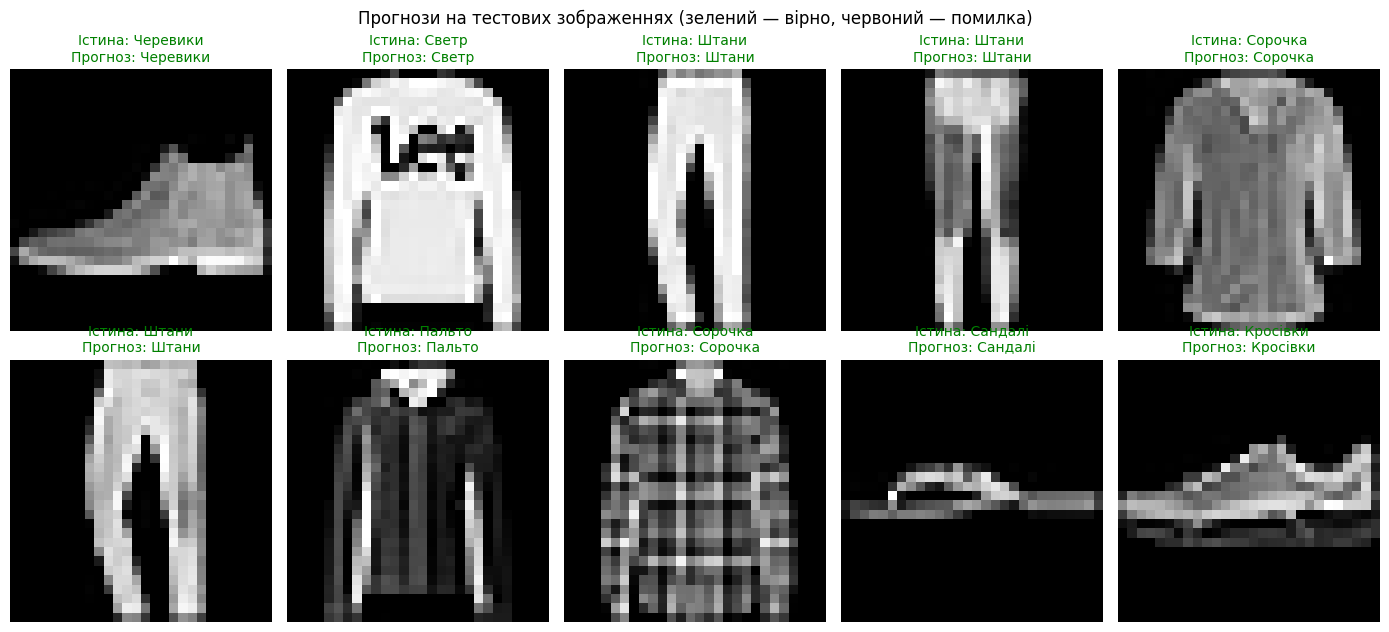

In [11]:
plt.figure(figsize=(14, 6.5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    true_c, pred_c = class_names[y_test[i]], class_names[y_pred[i]]
    plt.title(f'Істина: {true_c}\nПрогноз: {pred_c}',
              color='green' if y_test[i] == y_pred[i] else 'red', fontsize=10)
    plt.axis('off')
plt.suptitle('Прогнози на тестових зображеннях (зелений — вірно, червоний — помилка)')
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

In [12]:
# Проміжний висновок формується з отриманих результатів
rep = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
f1_sorted = sorted(class_names, key=lambda c: rep[c]['f1-score'])
worst = f1_sorted[:3]
cm = confusion_matrix(y_test, y_pred)
np.fill_diagonal(cm, 0)
a, b = np.unravel_index(cm.argmax(), cm.shape)

ok = test_acc >= 0.87
text = f"""**Ваш висновок:**

Тестова accuracy моделі з завдання 1 становить **{test_acc:.4f}** (test loss = {test_loss:.4f}), тобто вимогу щодо мінімальної точності 0,87
**{'виконано' if ok else 'не виконано'}**. Найгірше розпізнаються класи: {', '.join(f"{c} (F1 = {rep[c]['f1-score']:.2f})" for c in worst)};
найчастіша помилка — «{class_names[a]}» прогнозується як «{class_names[b]}» ({cm[a, b]} випадків). Для Fashion MNIST типовою причиною є візуальна подібність
класів (верхній одяг, футболки, сорочки), які на зображенні 28×28 розрізнити складно. Найкраще розпізнаються {', '.join(f"{c} (F1 = {rep[c]['f1-score']:.2f})" for c in f1_sorted[-3:])}."""
display(Markdown(text))

**Ваш висновок:**

Тестова accuracy моделі з завдання 1 становить **0.8961** (test loss = 0.3065), тобто вимогу щодо мінімальної точності 0,87
**виконано**. Найгірше розпізнаються класи: Сорочка (F1 = 0.71), Светр (F1 = 0.82), Пальто (F1 = 0.83);
найчастіша помилка — «Сорочка» прогнозується як «Футболка» (129 випадків). Для Fashion MNIST типовою причиною є візуальна подібність
класів (верхній одяг, футболки, сорочки), які на зображенні 28×28 розрізнити складно. Найкраще розпізнаються Сумка (F1 = 0.98), Сандалі (F1 = 0.98), Штани (F1 = 0.98).

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [13]:
%pip install -q keras-tuner

import keras_tuner as kt
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
print('Keras Tuner:', kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:
# Дані вже нормалізовані (x_train, x_test у діапазоні [0; 1]).
# Те саме розбиття train/val, що й у завданні 1; x_test, y_test у пошук НЕ передаються.
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42, stratify=y_train)

print('train:', x_tr.shape, ' val:', x_val.shape, ' (test зарезервовано:', x_test.shape, ')')
print('Діапазон:', x_tr.min(), '-', x_tr.max())

train: (54000, 28, 28)  val: (6000, 28, 28)  (test зарезервовано: (10000, 28, 28) )
Діапазон: 0.0 - 1.0


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    # Кількість прихованих шарів: 1–3
    for i in range(hp.Int('num_layers', 1, 3)):
        # Кількість нейронів: 32–512 із кроком 32
        model.add(layers.Dense(
            hp.Int(f'units_{i}', min_value=32, max_value=512, step=32),
            activation='relu',
            kernel_regularizer=regularizers.l2(1e-4)))
        model.add(layers.Dropout(0.3))

    model.add(layers.Dense(10, activation='softmax'))

    # Швидкість навчання: 0,01 / 0,001 / 0,0001
    lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_dir',          # каталог збереження результатів пошуку
    project_name='fashion_mnist_tuning',
    overwrite=True,
    seed=42,
)
tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:
def make_callbacks():
    return [
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
    ]

# Пошук: лише навчальні та валідаційні дані
tuner.search(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=make_callbacks(),
    verbose=2,
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print('\nНайкращі гіперпараметри:')
for name, value in best_hp.values.items():
    print(f'  {name}: {value}')

# Перенавчання найкращої конфігурації зі збереженням історії
best_model = tuner.hypermodel.build(best_hp)
history_tuned = best_model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=make_callbacks(),
    verbose=2,
)
best_model.summary()

Trial 3 Complete [00h 01m 53s]
val_accuracy: 0.8921666741371155

Best val_accuracy So Far: 0.909166693687439
Total elapsed time: 00h 05m 47s

Найкращі гіперпараметри:
  num_layers: 1
  units_0: 480
  learning_rate: 0.001
  units_1: 288
Epoch 1/50
422/422 - 7s - 15ms/step - accuracy: 0.8030 - loss: 0.6135 - val_accuracy: 0.8512 - val_loss: 0.4641 - learning_rate: 0.0010
Epoch 2/50
422/422 - 5s - 11ms/step - accuracy: 0.8522 - loss: 0.4688 - val_accuracy: 0.8592 - val_loss: 0.4299 - learning_rate: 0.0010
Epoch 3/50
422/422 - 5s - 11ms/step - accuracy: 0.8623 - loss: 0.4327 - val_accuracy: 0.8712 - val_loss: 0.4038 - learning_rate: 0.0010
Epoch 4/50
422/422 - 6s - 14ms/step - accuracy: 0.8698 - loss: 0.4119 - val_accuracy: 0.8793 - val_loss: 0.3830 - learning_rate: 0.0010
Epoch 5/50
422/422 - 5s - 11ms/step - accuracy: 0.8737 - loss: 0.3991 - val_accuracy: 0.8833 - val_loss: 0.3766 - learning_rate: 0.0010
Epoch 6/50
422/422 - 5s - 12ms/step - accuracy: 0.8778 - loss: 0.3873 - val_accuracy

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,144,832 (4.37 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 763,222 (2.91 MB)

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test loss     : 0.3349
Test accuracy : 0.8971


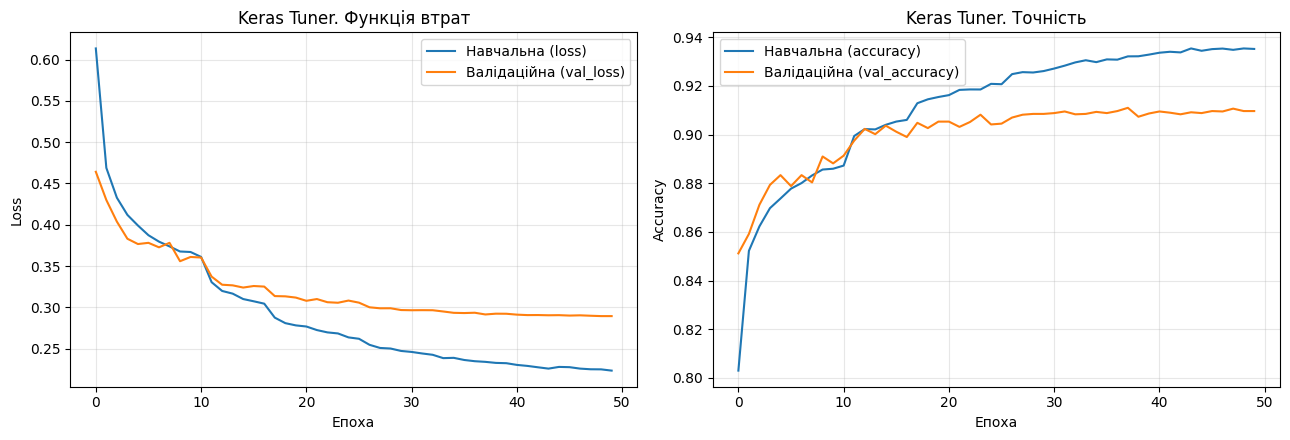

In [18]:
tuned_test_loss, tuned_test_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss     : {tuned_test_loss:.4f}')
print(f'Test accuracy : {tuned_test_acc:.4f}')

plot_history(history_tuned, 'Keras Tuner. ')

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |  |  |
| Кількість нейронів |  |  |
| Швидкість навчання |  |  |
| Точність на тестовій вибірці (accuracy) |  |  |
| Втрати на тестовій вибірці (loss) |  |  |
| Кількість епох навчання |  |  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
_..._

In [19]:
# Таблиця порівняння формується з результатів обох моделей
def dense_units(m):
    return [l.units for l in m.layers if hasattr(l, 'units')][:-1]   # без вихідного шару

units1 = dense_units(model)
units2 = dense_units(best_model)
lr2 = best_hp.values['learning_rate']
epochs1 = len(history.history['loss'])
epochs2 = len(history_tuned.history['loss'])

table = f"""| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | {len(units1)} | {len(units2)} |
| Кількість нейронів | {', '.join(map(str, units1))} | {', '.join(map(str, units2))} |
| Швидкість навчання | {LEARNING_RATE_1} | {lr2} |
| Точність на тестовій вибірці (accuracy) | {test_acc:.4f} | {tuned_test_acc:.4f} |
| Втрати на тестовій вибірці (loss) | {test_loss:.4f} | {tuned_test_loss:.4f} |
| Кількість епох навчання | {epochs1} | {epochs2} |"""
display(Markdown(table))

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 1 |
| Кількість нейронів | 256, 128 | 480 |
| Швидкість навчання | 0.001 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8961 | 0.8971 |
| Втрати на тестовій вибірці (loss) | 0.3065 | 0.3349 |
| Кількість епох навчання | 37 | 50 |

In [20]:
# Власні висновки формуються з отриманих чисел
diff = tuned_test_acc - test_acc
improved = diff > 0
rep = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
hard = sorted(class_names, key=lambda c: rep[c]['f1-score'])[:3]

if abs(diff) < 0.003:
    effect = 'практично не змінила'
else:
    effect = 'покращила' if improved else 'не покращила (стала гіршою)'

text = f"""**Власні висновки:**

1. **Поріг 0,87 у завданні 1:** тестова accuracy = {test_acc:.4f} — вимогу {'виконано' if test_acc >= 0.87 else 'не виконано'}.
2. **Вплив Keras Tuner:** після автоматичного підбору тестова accuracy = {tuned_test_acc:.4f} (різниця {diff:+.4f} відносно завдання 1), тобто оптимізація
   {effect} якість на тестовій вибірці. Слід враховувати, що RandomSearch із 3 спробами лише вибірково досліджує простір пошуку, тому виграш над розумно підібраною ручною конфігурацією не гарантований.
3. **Найкращі гіперпараметри:** {best_hp.values['num_layers']} прихован(их) шар(ів) із нейронами {units2} та швидкість навчання {lr2}.
   Результат відрізняється між запусками, бо випадковими є ініціалізація ваг, перемішування батчів і dropout, RandomSearch
   випадково обирає конфігурації (лише 3 спроби), а EarlyStopping і ReduceLROnPlateau зупиняють навчання на різних епохах.
4. **Найскладніші класи:** {', '.join(hard)} — за F1-score вони найгірші в завданні 1. Для Fashion MNIST складнощі зазвичай виникають між візуально схожими класами (футболка, сорочка, светр, пальто),
   які на зображенні 28×28 мають близькі силуети; водночас штани, сумки та взуття розпізнаються краще."""
display(Markdown(text))

**Власні висновки:**

1. **Поріг 0,87 у завданні 1:** тестова accuracy = 0.8961 — вимогу виконано.
2. **Вплив Keras Tuner:** після автоматичного підбору тестова accuracy = 0.8971 (різниця +0.0010 відносно завдання 1), тобто оптимізація
   практично не змінила якість на тестовій вибірці. Слід враховувати, що RandomSearch із 3 спробами лише вибірково досліджує простір пошуку, тому виграш над розумно підібраною ручною конфігурацією не гарантований.
3. **Найкращі гіперпараметри:** 1 прихован(их) шар(ів) із нейронами [480] та швидкість навчання 0.001.
   Результат відрізняється між запусками, бо випадковими є ініціалізація ваг, перемішування батчів і dropout, RandomSearch
   випадково обирає конфігурації (лише 3 спроби), а EarlyStopping і ReduceLROnPlateau зупиняють навчання на різних епохах.
4. **Найскладніші класи:** Сорочка, Светр, Пальто — за F1-score вони найгірші в завданні 1. Для Fashion MNIST складнощі зазвичай виникають між візуально схожими класами (футболка, сорочка, светр, пальто),
   які на зображенні 28×28 мають близькі силуети; водночас штани, сумки та взуття розпізнаються краще.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.